# Lottery Ticket Hypothesis — analysis

Reads only `results/` (written by `export_results.py`); no GPU or checkpoints needed.
Every figure is also saved to `results/figures/`.

**Conditions (2×2 controls)**

| condition | mask | initialization |
|---|---|---|
| winning ticket | IMP mask | original |
| random reinit | IMP mask | fresh random |
| random mask | random, same per-layer counts | original |
| fully random | random, same per-layer counts | fresh random |

**Predefined analysis choices** (fixed before looking at Fashion-MNIST):
- Iterations-to-accuracy threshold: **97% validation accuracy**; runs that never reach it within the budget are shown as "not reached".
- Tolerance: a level is **outside tolerance** when its test accuracy (early-stopping criterion) is more than **0.5 percentage points** below the dense network's.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATASET = 'mnist'          # 'mnist' or 'fashion_mnist'
THRESHOLD = 0.97           # validation accuracy for iterations-to-accuracy
TOLERANCE = 0.005          # 0.5 percentage points below the dense baseline
RESULTS = Path('results')
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

CONDITIONS = ['ticket', 'reinit', 'random_mask', 'random_both']
LABELS = {'ticket': 'Winning ticket', 'reinit': 'Random reinit',
          'random_mask': 'Random mask', 'random_both': 'Fully random'}
# Categorical palette, fixed order (validated for colour-vision deficiency, light surface).
COLORS = {'ticket': '#2a78d6', 'reinit': '#eb6834', 'random_mask': '#1baf7a', 'random_both': '#eda100'}
MARKERS = {'ticket': 'o', 'reinit': 's', 'random_mask': '^', 'random_both': 'D'}
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10, 'axes.titlesize': 11,
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': 0.8, 'legend.frameon': False,
})

## Load results
One folder per IMP seed. All folders for the dataset must share the same settings apart from the seed.

In [2]:
def load_run(folder):
    cfg = json.loads((folder / 'config.json').read_text())
    parts = [pd.read_csv(folder / 'summary.csv').assign(condition='ticket')]
    for c in CONDITIONS[1:]:
        path = folder / 'controls' / c / 'summary.csv'
        if path.exists():
            parts.append(pd.read_csv(path).assign(condition=c))
    summary = pd.concat(parts, ignore_index=True).assign(seed=cfg['seed'])
    hist = pd.read_csv(folder / 'histories.csv').assign(seed=cfg['seed'])
    return cfg, summary, hist

runs = [load_run(f) for f in sorted(RESULTS.iterdir())
        if (f / 'config.json').exists() and json.loads((f / 'config.json').read_text())['dataset'] == DATASET]
assert runs, f'no results for {DATASET}'
IGNORE = {'seed', 'out', 'device', 'no_progress'}
settings = [{k: v for k, v in cfg.items() if k not in IGNORE} for cfg, _, _ in runs]
assert all(s == settings[0] for s in settings), 'result folders use different settings'
SETTINGS = settings[0]
summary = pd.concat([s for _, s, _ in runs], ignore_index=True)
hist = pd.concat([h for _, _, h in runs], ignore_index=True)
SEEDS = sorted(int(x) for x in summary.seed.unique())
STEPS = SETTINGS['steps']
print(f"{DATASET}: seeds {SEEDS}; {SETTINGS['optimizer']} lr={SETTINGS['lr']}, {STEPS} steps/level, "
      f"{SETTINGS['rounds']} rounds, {SETTINGS['pruning']} pruning")

mnist: seeds [1, 2, 42]; adam lr=0.0012, 50000 steps/level, 15 rounds, layerwise pruning


In [3]:
def steps_to_threshold(h):
    hit = h.loc[h.val_accuracy >= THRESHOLD, 'step']
    return hit.iloc[0] if len(hit) else np.nan

reach = (hist.groupby(['seed', 'condition', 'level'])
             .apply(steps_to_threshold, include_groups=False).rename('steps_to_threshold').reset_index())
summary = summary.merge(reach, on=['seed', 'condition', 'level'], how='left')

def agg(col):
    # mean / std / n over seeds, per condition and level
    g = summary.groupby(['condition', 'level'])
    out = g.agg(weights_remaining=('weights_remaining', 'first'), mean=(col, 'mean'),
                std=(col, 'std'), n=(col, 'count')).reset_index()
    return out

dense = summary.query("condition == 'ticket' and level == 0")
DENSE_ACC = dense.best_test_accuracy.mean()
DENSE_END = dense.end_test_accuracy.mean()

## Helpers
x axis: percent of weights remaining on a log scale, dense on the left. With one seed each point is a single run;
with several seeds the line is the mean and the band is ±1 standard deviation.

In [4]:
LEVEL_TICKS = summary.query("condition == 'ticket'").groupby('level').weights_remaining.first()

def pct_axis(ax):
    ax.set_xscale('log')
    ax.set_xlim(1.15, LEVEL_TICKS.min() * 0.85)   # reversed: dense on the left
    ticks = [1.0, 0.512, 0.262, 0.135, 0.0695, 0.0358]
    ax.set_xticks(ticks)
    ax.set_xticklabels([f'{t*100:.3g}' for t in ticks])
    ax.minorticks_off()
    ax.set_xlabel('Weights remaining (%)')

def spread(ys, gap):
    """Move positions (in points) apart by at least `gap`, keeping each cluster centred on its originals."""
    order = sorted(range(len(ys)), key=lambda i: ys[i])
    groups = [[i] for i in order]
    def place(g):
        c = np.mean([ys[i] for i in g])
        return [c + (k - (len(g) - 1) / 2) * gap for k in range(len(g))]
    merged = True
    while merged:
        merged = False
        for j in range(len(groups) - 1):
            if place(groups[j])[-1] + gap > place(groups[j + 1])[0]:
                groups[j:j + 2] = [groups[j] + groups[j + 1]]
                merged = True
                break
    out = [0.0] * len(ys)
    for g in groups:
        for i, y in zip(g, place(g)):
            out[i] = y
    return out

def label_ends(ax, ends, gap=10):
    """Direct labels at the line ends, nudged apart. Call after the axis limits and layout are final."""
    if not ends:
        return
    to_pt = 72 / ax.figure.dpi
    ys = [ax.transData.transform((x, y))[1] * to_pt for _, x, y in ends]
    for (text, x, y), y0, y1 in zip(ends, ys, spread(ys, gap)):
        ax.annotate(text, (x, y), xytext=(6, y1 - y0), textcoords='offset points',
                    va='center', fontsize=8.5, color=INK, annotation_clip=False)

def plot_metric(ax, col, scale=1.0):
    """Mean over seeds (+-1 std band). Returns the line ends for label_ends()."""
    ends = []
    for c in CONDITIONS:
        a = agg(col).query('condition == @c').sort_values('level')
        if a.empty:
            continue
        x, y = a.weights_remaining, a['mean'] * scale
        ax.plot(x, y, color=COLORS[c], marker=MARKERS[c], ms=5, lw=1.8, label=LABELS[c],
                markeredgecolor='white', markeredgewidth=0.8)
        if (a.n > 1).any():
            ax.fill_between(x, (a['mean'] - a['std']) * scale, (a['mean'] + a['std']) * scale,
                            color=COLORS[c], alpha=0.15, lw=0)
        ends.append((LABELS[c], x.iloc[-1], y.iloc[-1]))
    return ends

def seeds_note():
    return f'seed {SEEDS[0]}' if len(SEEDS) == 1 else f'mean over seeds {SEEDS}'

def save(fig, name):
    fig.savefig(FIGURES / f'{DATASET}_{name}.png', bbox_inches='tight')

## Figure 1 — Test accuracy vs. weights remaining
Left: accuracy at the minimum-validation-loss checkpoint (early stopping). Right: accuracy at the end of the
fixed training budget. Dashed line: dense network; shaded strip: within the 0.5-point tolerance.

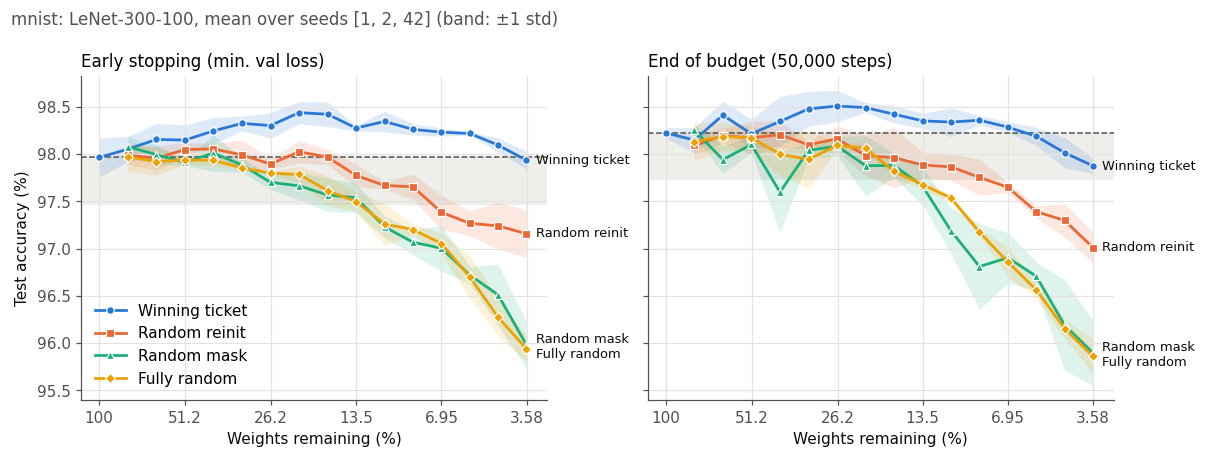

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
ends = []
for ax, col, base, title in [(axes[0], 'best_test_accuracy', DENSE_ACC, 'Early stopping (min. val loss)'),
                             (axes[1], 'end_test_accuracy', DENSE_END, f'End of budget ({STEPS:,} steps)')]:
    ax.axhspan((base - TOLERANCE) * 100, base * 100, color=GRID, alpha=0.6, lw=0)
    ax.axhline(base * 100, color=MUTED, ls='--', lw=1)
    ends.append(plot_metric(ax, col, scale=100))
    pct_axis(ax)
    ax.set_title(title, loc='left')
axes[0].set_ylabel('Test accuracy (%)')
axes[0].legend(loc='lower left')
fig.suptitle(f'{DATASET}: LeNet-300-100, {seeds_note()} (band: ±1 std)' if len(SEEDS) > 1
             else f'{DATASET}: LeNet-300-100, {seeds_note()}', x=0.01, ha='left', fontsize=11, color=MUTED)
fig.tight_layout()
for ax, e in zip(axes, ends):
    label_ends(ax, e)
fig.tight_layout()   # again, so the end labels get room
save(fig, 'accuracy_vs_sparsity')

## Figure 2 — Early-stopping iteration vs. weights remaining
The step with the lowest validation loss: a proxy for how fast each network learns (paper, Figure 4).

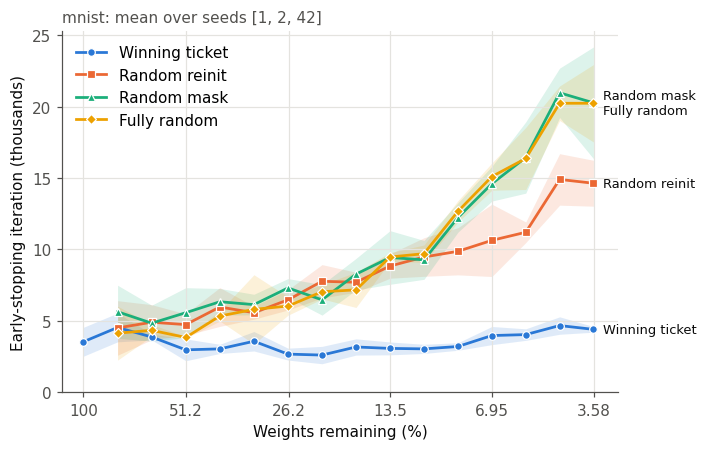

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ends = plot_metric(ax, 'best_step', scale=1e-3)
pct_axis(ax)
ax.set_ylabel('Early-stopping iteration (thousands)')
ax.set_ylim(bottom=0)
ax.legend(loc='upper left')
ax.set_title(f'{DATASET}: {seeds_note()}', loc='left', fontsize=10, color=MUTED)
fig.tight_layout()
label_ends(ax, ends)
fig.tight_layout()   # again, so the end labels get room
save(fig, 'early_stop_iteration')

## Figure 3 — Iterations to reach 97% validation accuracy
Filled markers and line: mean over seeds, drawn only where **every** seed reached the threshold.
Open marker with "k/n": only k of the n seeds reached it; the point is the mean of those k, so the true
cost is higher. Levels where no seed reached it within the budget are drawn in the shaded "not reached" strip,
one row per condition.

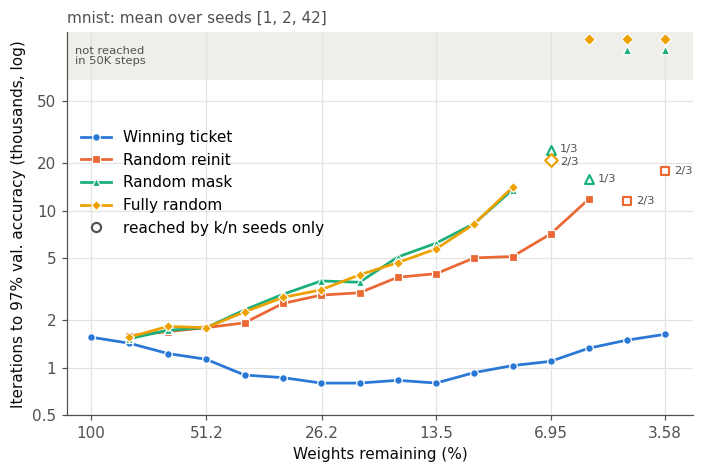

In [7]:
from matplotlib.lines import Line2D

def reach_stats(c):
    s = summary.query('condition == @c')
    return s.groupby('level').agg(w=('weights_remaining', 'first'), mean=('steps_to_threshold', 'mean'),
                                  reached=('steps_to_threshold', 'count'), n=('seed', 'count')).reset_index()

fig, ax = plt.subplots(figsize=(6.5, 4.4))
top = STEPS * 1e-3
partial_labels = []
for c in CONDITIONS:
    if summary.query('condition == @c').empty:
        continue
    g = reach_stats(c)
    full = g['mean'].where(g.reached == g.n)          # NaN breaks the line where a seed missed
    ax.plot(g.w, full * 1e-3, color=COLORS[c], marker=MARKERS[c], ms=5, lw=1.8, label=LABELS[c],
            markeredgecolor='white', markeredgewidth=0.8)
    part = g[(g.reached > 0) & (g.reached < g.n)]
    ax.scatter(part.w, part['mean'] * 1e-3, marker=MARKERS[c], s=34, facecolor='white',
               edgecolor=COLORS[c], linewidth=1.4, zorder=3)
    partial_labels += [(f'{int(r.reached)}/{int(r.n)}', r.w, r['mean'] * 1e-3) for _, r in part.iterrows()]
    none = g[g.reached == 0]
    row_y = top * 1.5 * 1.18 ** CONDITIONS.index(c)   # one 'not reached' row per condition
    ax.scatter(none.w, np.full(len(none), row_y), marker=MARKERS[c], s=30, color=COLORS[c],
               edgecolor='white', linewidth=0.8, zorder=3)
ax.axhspan(top * 1.35, top * 1.5 * 1.18 ** 3.6, color=GRID, alpha=0.6, lw=0, zorder=0)
ax.text(1.1, top * 1.5 * 1.18 ** 1.5, f'not reached\nin {STEPS // 1000}K steps', va='center', ha='left',
        fontsize=7.5, color=MUTED, linespacing=1.0)
ax.set_yscale('log')
ax.set_ylim(0.5, top * 1.5 * 1.18 ** 3.6)
yt = [t for t in (0.5, 1, 2, 5, 10, 20, 50) if t <= top]
ax.set_yticks(yt)
ax.set_yticklabels([f'{t:g}' for t in yt])
ax.minorticks_off()
ax.set_ylabel(f'Iterations to {THRESHOLD:.0%} val. accuracy (thousands, log)')
pct_axis(ax)
handles, labels = ax.get_legend_handles_labels()
if partial_labels:
    handles.append(Line2D([], [], marker='o', ls='', mfc='white', mec=MUTED, mew=1.4, ms=6))
    labels.append('reached by k/n seeds only')
ax.legend(handles, labels, loc='upper left', bbox_to_anchor=(0, 0.78))
ax.set_title(f'{DATASET}: {seeds_note()}', loc='left', fontsize=10, color=MUTED)
fig.tight_layout()
# k/n labels right of the open markers; labels at the same level are nudged apart.
to_pt = 72 / fig.dpi
for x in sorted({x for _, x, _ in partial_labels}):
    items = [p for p in partial_labels if p[1] == x]
    ys = [ax.transData.transform((x, y))[1] * to_pt for _, _, y in items]
    for (text, _, y), y0, y1 in zip(items, ys, spread(ys, 9)):
        ax.annotate(text, (x, y), xytext=(6, y1 - y0), textcoords='offset points', va='center',
                    fontsize=7.5, color=MUTED)
save(fig, 'iterations_to_threshold')

## Figure 4 — Validation accuracy during training
Three sparsity levels; first 20,000 steps (curves are flat afterwards). With several seeds the curve is the
mean over seeds at each evaluation step.

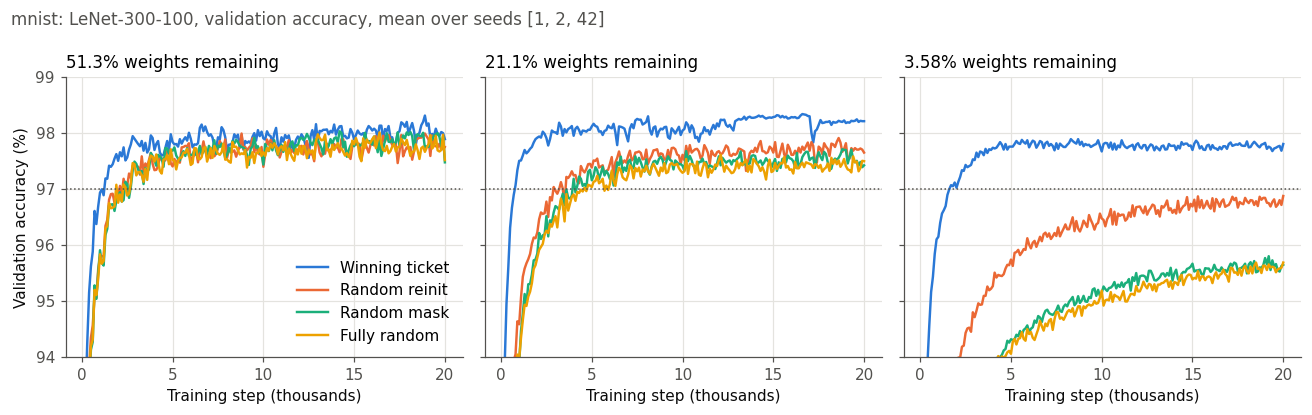

In [8]:
show_levels = [lvl for lvl in (3, 7, 15) if lvl in LEVEL_TICKS.index]
fig, axes = plt.subplots(1, len(show_levels), figsize=(4 * len(show_levels), 3.8), sharey=True)
axes = np.atleast_1d(axes)
for ax, lvl in zip(axes, show_levels):
    for c in CONDITIONS:
        h = hist.query('condition == @c and level == @lvl and step <= 20000')
        if h.empty:
            continue
        m = h.groupby('step').val_accuracy.mean()
        ax.plot(m.index * 1e-3, m.values * 100, color=COLORS[c], lw=1.6, label=LABELS[c])
    ax.axhline(THRESHOLD * 100, color=MUTED, ls=':', lw=1)
    ax.set_title(f'{LEVEL_TICKS[lvl]*100:.3g}% weights remaining', loc='left')
    ax.set_xlabel('Training step (thousands)')
    ax.set_ylim(94, 99)
axes[0].set_ylabel('Validation accuracy (%)')
axes[0].legend(loc='lower right')
fig.suptitle(f'{DATASET}: LeNet-300-100, validation accuracy, {seeds_note()}', x=0.01, ha='left',
             fontsize=11, color=MUTED)
fig.tight_layout()
save(fig, 'learning_curves')

## Tolerance: where does accuracy leave the dense baseline?
First pruning level whose test accuracy (early stopping, mean over seeds) is more than 0.5 points below the dense network.

In [9]:
limit = DENSE_ACC - TOLERANCE
rows = []
for c in CONDITIONS:
    a = agg('best_test_accuracy').query('condition == @c').sort_values('level')
    if a.empty:
        continue
    out = a[a['mean'] < limit]
    first = out.iloc[0] if len(out) else None
    rows.append({'condition': LABELS[c],
                 'first level outside tolerance': '—' if first is None else int(first.level),
                 'weights remaining there (%)': '— (within at all levels)' if first is None else round(first.weights_remaining * 100, 2),
                 'accuracy there (%)': '—' if first is None else round(first['mean'] * 100, 2)})
print(f'Dense test accuracy {DENSE_ACC:.2%}; tolerance limit {limit:.2%}')
pd.DataFrame(rows)

Dense test accuracy 97.96%; tolerance limit 97.46%


,condition,first level outside tolerance,weights remaining there (%),accuracy there (%)
0,Winning ticket,—,— (within at all levels),—
1,Random reinit,12,6.95,97.38
2,Random mask,10,10.83,97.23
3,Fully random,10,10.83,97.26


## Table — all numbers
Test accuracy (%), early-stopping iteration: mean over seeds. Iterations to the threshold: mean over the seeds
that reached it, with "(k/n)" when only k of n seeds did; "not reached" when none did.

In [10]:
def table(col, scale=1.0, decimals=2):
    t = agg(col).assign(value=lambda d: (d['mean'] * scale).round(decimals))
    t = t.pivot(index='level', columns='condition', values='value').reindex(columns=CONDITIONS)
    t.insert(0, 'weights remaining (%)', LEVEL_TICKS.reindex(t.index).mul(100).round(2))
    return t.rename(columns=LABELS)

def reach_table():
    cols = {}
    for c in CONDITIONS:
        if summary.query('condition == @c').empty:
            continue
        g = reach_stats(c).set_index('level')
        cols[LABELS[c]] = [('not reached' if r.reached == 0 else f'{r["mean"]:.0f}' if r.reached == r.n
                            else f'{r["mean"]:.0f} ({int(r.reached)}/{int(r.n)})') for _, r in g.iterrows()]
        cols[LABELS[c]] = pd.Series(cols[LABELS[c]], index=g.index)
    t = pd.DataFrame(cols).reindex(LEVEL_TICKS.index).fillna('')
    t.insert(0, 'weights remaining (%)', LEVEL_TICKS.mul(100).round(2))
    return t

pd.set_option('display.width', 140)
print('Test accuracy (%), early stopping'); display(table('best_test_accuracy', 100))
print('Test accuracy (%), end of budget'); display(table('end_test_accuracy', 100))
print('Early-stopping iteration'); display(table('best_step', 1, 0))
print(f'Iterations to {THRESHOLD:.0%} validation accuracy'); display(reach_table())

Test accuracy (%), early stopping


condition,weights remaining (%),Winning ticket,Random reinit,Random mask,Fully random
level,,,,,
0,100.00,97.96,NaN,NaN,NaN
1,80.04,98.05,97.99,98.08,97.97
2,64.06,98.15,97.95,97.99,97.92
3,51.28,98.15,98.05,97.91,97.94
4,41.05,98.24,98.05,98.01,97.93
5,32.87,98.32,97.99,97.88,97.85
6,26.32,98.30,97.89,97.70,97.80
7,21.07,98.44,98.02,97.66,97.78
8,16.88,98.42,97.97,97.57,97.61


Test accuracy (%), end of budget


condition,weights remaining (%),Winning ticket,Random reinit,Random mask,Fully random
level,,,,,
0,100.00,98.22,NaN,NaN,NaN
1,80.04,98.15,98.09,98.25,98.13
2,64.06,98.41,98.19,97.94,98.18
3,51.28,98.21,98.17,98.10,98.17
4,41.05,98.34,98.20,97.60,98.00
5,32.87,98.48,98.10,98.04,97.94
6,26.32,98.51,98.16,98.08,98.09
7,21.07,98.49,97.98,97.88,98.06
8,16.88,98.42,97.96,97.88,97.82


Early-stopping iteration


condition,weights remaining (%),Winning ticket,Random reinit,Random mask,Fully random
level,,,,,
0,100.00,3533.0,NaN,NaN,NaN
1,80.04,4533.0,4500.0,5633.0,4133.0
2,64.06,3867.0,4900.0,4833.0,4333.0
3,51.28,2967.0,4733.0,5567.0,3833.0
4,41.05,3033.0,5967.0,6333.0,5333.0
5,32.87,3567.0,5567.0,6133.0,5800.0
6,26.32,2667.0,6467.0,7300.0,6033.0
7,21.07,2600.0,7767.0,6467.0,7033.0
8,16.88,3167.0,7700.0,8267.0,7167.0


Iterations to 97% validation accuracy


,weights remaining (%),Winning ticket,Random reinit,Random mask,Fully random
level,,,,,
0,100.00,1567,,,
1,80.04,1433,1600,1533,1567
2,64.06,1233,1700,1733,1833
3,51.28,1133,1800,1800,1800
4,41.05,900,1933,2333,2267
5,32.87,867,2567,2933,2800
6,26.32,800,2900,3567,3133
7,21.07,800,3000,3500,3900
8,16.88,833,3767,5067,4667
